In [1]:
!git clone -q https://github.com/esa/SpOC2.git
%cd "/kaggle/working/SpOC2/Morphing Rovers"
!mkdir -p data/spoc2/morphing && cp -r data/Maps data/coordinates.txt data/example_rover.npy data/spoc2/morphing/
!sed -i "77s/.*/HEIGHTMAP_NAMES = ['Map1.jpg', 'Map2.jpg', 'Map3.jpg', 'Map4.jpg', 'Map5.jpg', 'Map6.jpg']/" morphing_udp.py
!sed -i '683s/, angle,/, float(angle),/' morphing_udp.py

/kaggle/working/SpOC2/Morphing Rovers


In [2]:
import numpy as np, time, torch
import matplotlib.pyplot as plt
from morphing_udp import morphing_rover_UDP

udp = morphing_rover_UDP()
x = udp.example()
print("GPU e disponueshme:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Emri i GPU-së:", torch.cuda.get_device_name(0))

GPU e disponueshme: True
Emri i GPU-së: Tesla T4


In [3]:
kohet = []
for i in range(3):
    t = time.time()
    nota = udp.fitness(x)[0]
    kohet.append(time.time() - t)
    print(f"Matja {i+1}: nota {nota:.3f}, koha {kohet[-1]:.1f} s")
print(f"Mesatarja: {np.mean(kohet):.1f} s për një rover")

Matja 1: nota 7.984, koha 23.8 s
Matja 2: nota 7.984, koha 23.9 s
Matja 3: nota 7.984, koha 24.1 s
Mesatarja: 23.9 s për një rover


In [4]:
dev = "cuda"
shtresa_cpu = torch.nn.Conv2d(1, 16, 5)
shtresa_gpu = torch.nn.Conv2d(1, 16, 5).to(dev)
N_lista = [1, 10, 100, 1000]
koha_cpu, koha_gpu = [], []

for N in N_lista:
    terreni = torch.randn(N, 1, 64, 64)
    t = time.time()
    for _ in range(20): shtresa_cpu(terreni)
    koha_cpu.append(time.time() - t)

    terreni_gpu = terreni.to(dev)
    shtresa_gpu(terreni_gpu); torch.cuda.synchronize()
    t = time.time()
    for _ in range(20): shtresa_gpu(terreni_gpu)
    torch.cuda.synchronize()
    koha_gpu.append(time.time() - t)
    print(f"{N} rovera: CPU {koha_cpu[-1]:.4f} s, GPU {koha_gpu[-1]:.4f} s")

1 rovera: CPU 0.0071 s, GPU 0.0013 s
10 rovera: CPU 0.0181 s, GPU 0.0015 s
100 rovera: CPU 0.1212 s, GPU 0.0111 s
1000 rovera: CPU 4.4051 s, GPU 0.1184 s


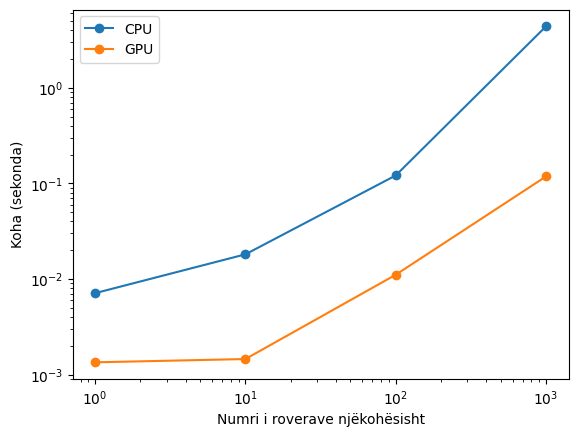

In [5]:
plt.plot(N_lista, koha_cpu, marker="o", label="CPU")
plt.plot(N_lista, koha_gpu, marker="o", label="GPU")
plt.xscale("log"); plt.yscale("log")
plt.xlabel("Numri i roverave njëkohësisht")
plt.ylabel("Koha (sekonda)")
plt.legend()
plt.show()